In [1]:
import torch
import torchvision

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CPU check:", torch.tensor([1, 2, 3]).sum().item())

PyTorch: 2.14.1+cpu
Torchvision: 0.29.1+cpu
CPU check: 6


In [2]:
from torchvision.models import ResNet18_Weights, resnet18

weights = ResNet18_Weights.IMAGENET1K_V1
model = resnet18(weights=weights)
model.eval()

print("Pretrained ResNet-18 is ready.")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 169MB/s]


Pretrained ResNet-18 is ready.


Saving dog_photo.png to dog_photo.png


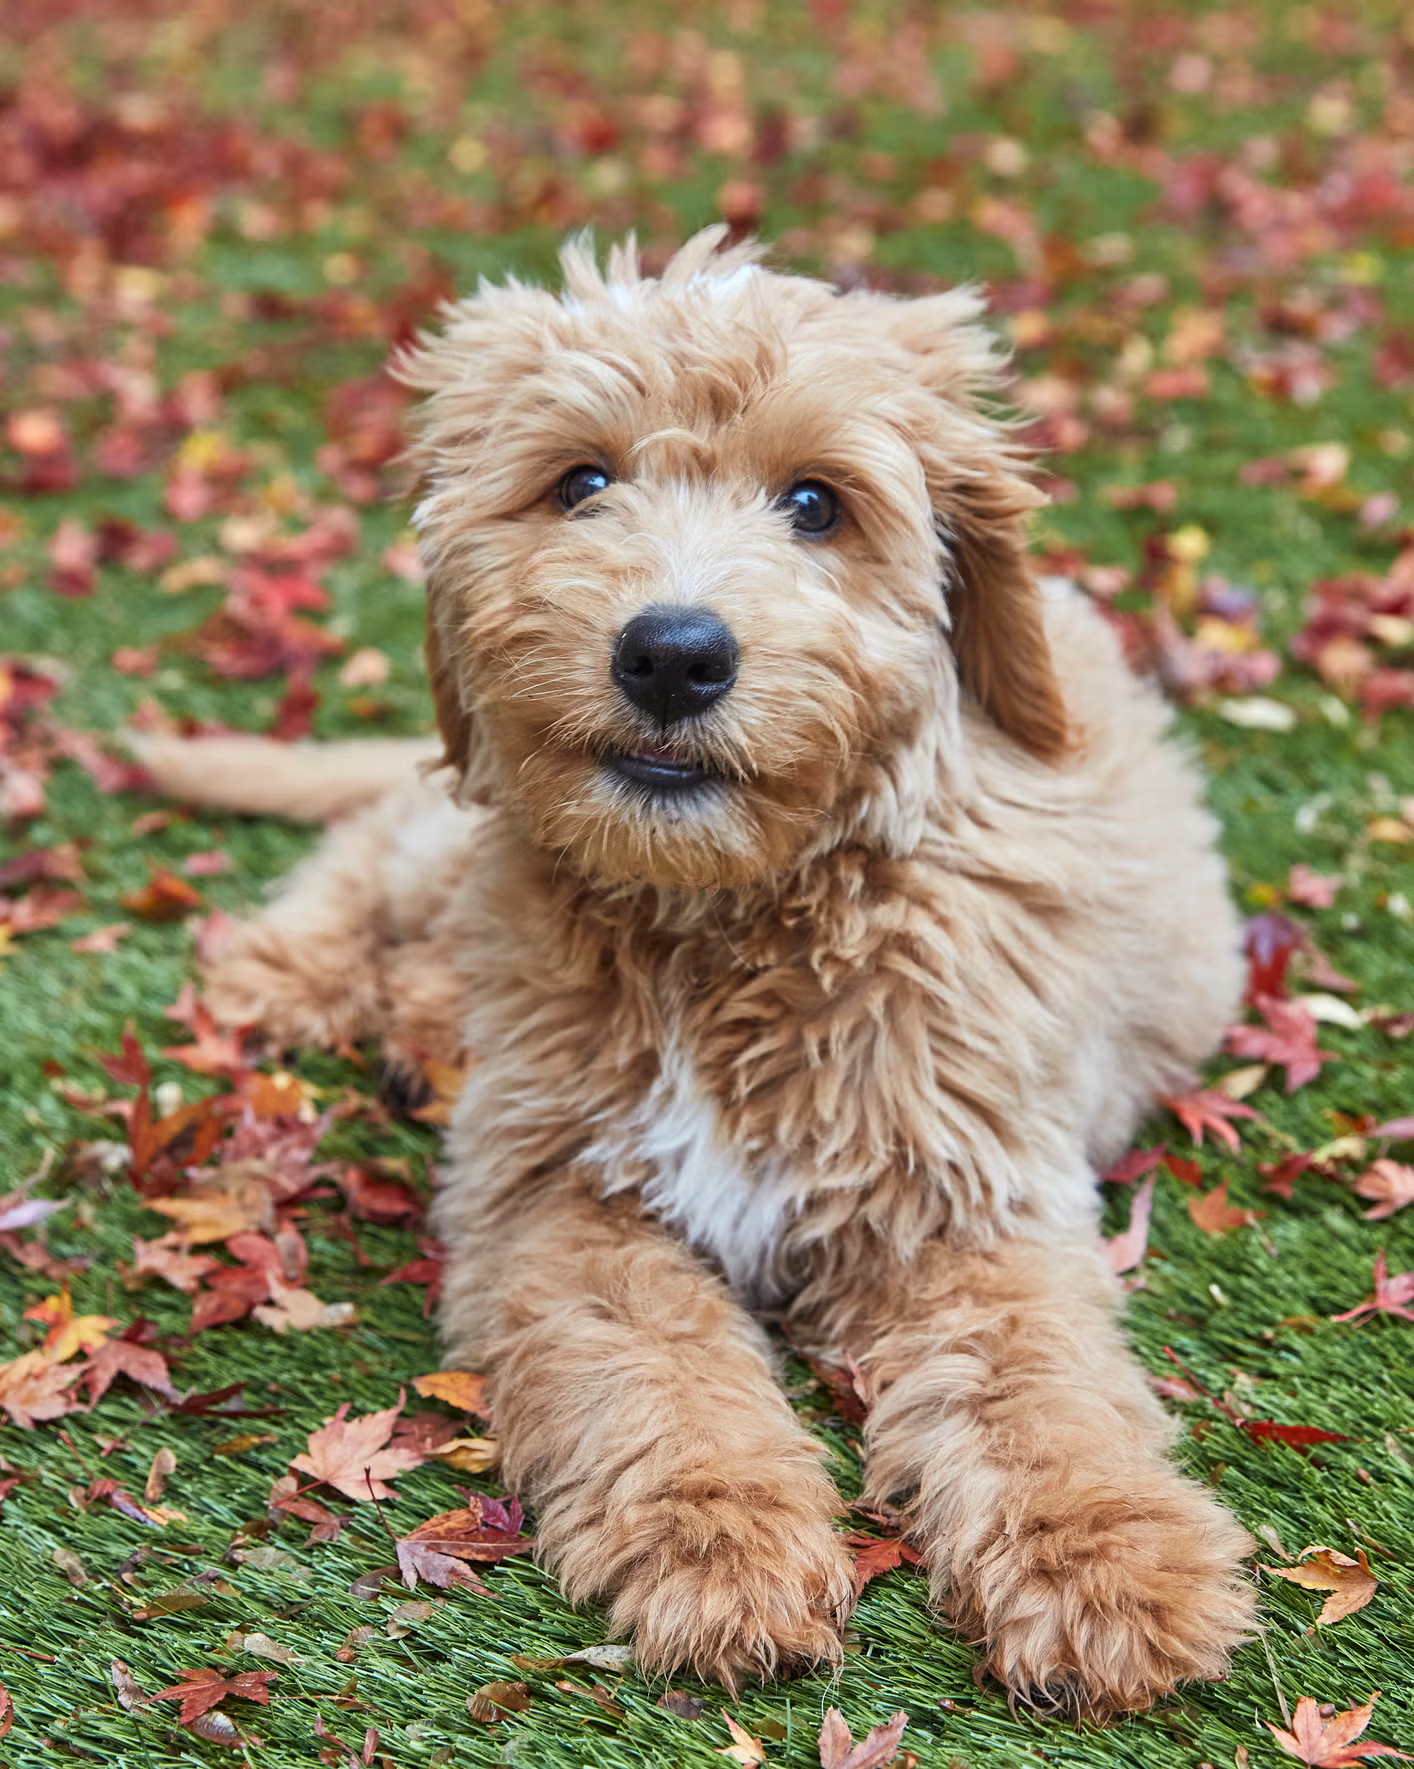

Predicted class: miniature poodle
Class index: 266


In [3]:
import torch
from google.colab import files
from PIL import Image
from IPython.display import display

uploaded = files.upload()
image_name = next(iter(uploaded))
image = Image.open(image_name).convert("RGB")

# Apply the preprocessing that matches the pretrained weights.
input_batch = weights.transforms()(image).unsqueeze(0)

# Get the model's scores for this image.
with torch.no_grad():
    scores = model(input_batch)

target_class = scores[0].argmax().item()
class_name = weights.meta["categories"][target_class]

display(image)
print("Predicted class:", class_name)
print("Class index:", target_class)

In [4]:
captured = []

def save_feature_maps(module, inputs, output):
    captured.append(output)

hook = model.layer4[-1].register_forward_hook(save_feature_maps)
logits = model(input_batch)
hook.remove()

feature_maps = captured[0]
print("Feature map shape:", feature_maps.shape)

Feature map shape: torch.Size([1, 512, 7, 7])


In [5]:
class_score = logits[0, target_class]
gradients = torch.autograd.grad(class_score, feature_maps)[0]
channel_weights = gradients.mean(dim=(2, 3), keepdim=True)

print("Gradient shape:", gradients.shape)
print("Weight shape:", channel_weights.shape)

Gradient shape: torch.Size([1, 512, 7, 7])
Weight shape: torch.Size([1, 512, 1, 1])


Heatmap shape: torch.Size([7, 7])


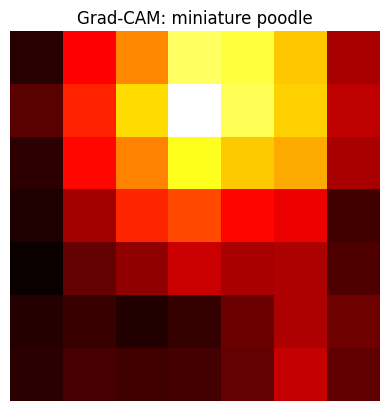

In [6]:
import matplotlib.pyplot as plt

weighted_maps = feature_maps.detach() * channel_weights
combined_map = weighted_maps.sum(dim=1)
gradcam = combined_map.relu()[0]

print("Heatmap shape:", gradcam.shape)

plt.imshow(gradcam.cpu(), cmap="hot", interpolation="nearest")
plt.title(f"Grad-CAM: {class_name}")
plt.axis("off")
plt.show()

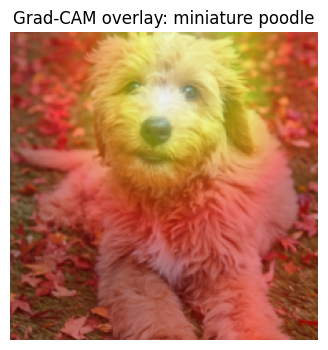

In [7]:
import torch.nn.functional as F

# Undo normalization so the model's input crop displays in natural colors.
preprocess = weights.transforms()
mean = torch.tensor(preprocess.mean).view(3, 1, 1)
std = torch.tensor(preprocess.std).view(3, 1, 1)
crop = (input_batch[0].cpu() * std + mean).clamp(0, 1)
crop = crop.permute(1, 2, 0)

# Resize the 7 × 7 heatmap to match the crop.
overlay = F.interpolate(
    gradcam[None, None],
    size=input_batch.shape[-2:],
    mode="bilinear",
    align_corners=False,
)[0, 0].cpu()

plt.figure(figsize=(4, 4))
plt.imshow(crop)
plt.imshow(overlay, cmap="hot", alpha=0.45, vmin=0)
plt.title(f"Grad-CAM overlay: {class_name}")
plt.axis("off")
plt.show()

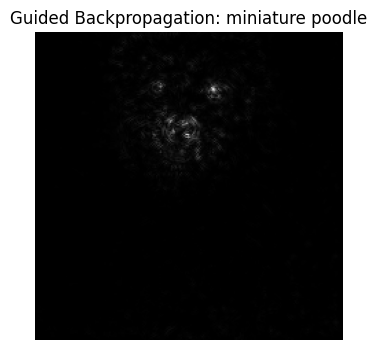

In [8]:
from copy import deepcopy

guided_model = deepcopy(model)
guided_input = input_batch.detach().clone().requires_grad_(True)

def keep_positive_gradients(module, grad_input, grad_output):
    return (grad_input[0].clamp(min=0),)

hooks = []
for layer in guided_model.modules():
    if isinstance(layer, torch.nn.ReLU):
        layer.inplace = False
        hooks.append(layer.register_full_backward_hook(keep_positive_gradients))

guided_score = guided_model(guided_input)[0, target_class]
guided_gradients = torch.autograd.grad(guided_score, guided_input)[0]

for hook in hooks:
    hook.remove()

guided_map = guided_gradients[0].abs().amax(dim=0).cpu()

plt.figure(figsize=(4, 4))
plt.imshow(guided_map, cmap="gray")
plt.title(f"Guided Backpropagation: {class_name}")
plt.axis("off")
plt.show()

In [9]:
torch.manual_seed(42)

randomized_model = deepcopy(model)
randomized_model.fc.reset_parameters()

with torch.no_grad():
    randomized_scores = randomized_model(input_batch)

print(f"Fixed target: {class_name} ({target_class})")
print(f"Pretrained score: {logits[0, target_class].item():.3f}")
print(f"After classifier reset: {randomized_scores[0, target_class].item():.3f}")

Fixed target: miniature poodle (266)
Pretrained score: 9.863
After classifier reset: -0.244


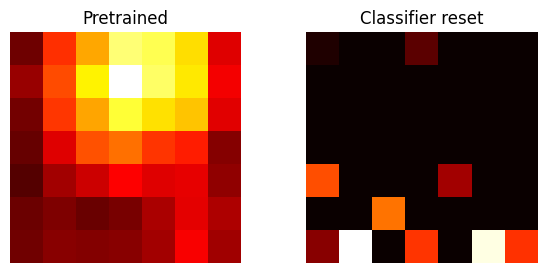

In [10]:
captured.clear()

hook = randomized_model.layer4[-1].register_forward_hook(save_feature_maps)
reset_logits = randomized_model(input_batch)
hook.remove()

reset_features = captured[0]
reset_score = reset_logits[0, target_class]
reset_gradients = torch.autograd.grad(reset_score, reset_features)[0]
reset_weights = reset_gradients.mean(dim=(2, 3), keepdim=True)
reset_gradcam = (reset_features.detach() * reset_weights).sum(dim=1).relu()[0]

fig, axes = plt.subplots(1, 2, figsize=(7, 3))

axes[0].imshow(gradcam.cpu(), cmap="hot", interpolation="nearest", vmin=0)
axes[0].set_title("Pretrained")
axes[0].axis("off")

axes[1].imshow(reset_gradcam.cpu(), cmap="hot", interpolation="nearest", vmin=0)
axes[1].set_title("Classifier reset")
axes[1].axis("off")

plt.show()

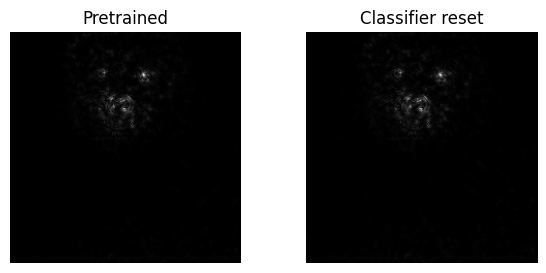

In [11]:
reset_guided_model = deepcopy(randomized_model)
reset_guided_input = input_batch.detach().clone().requires_grad_(True)

hooks = []
for layer in reset_guided_model.modules():
    if isinstance(layer, torch.nn.ReLU):
        layer.inplace = False
        hooks.append(layer.register_full_backward_hook(keep_positive_gradients))

reset_guided_score = reset_guided_model(reset_guided_input)[0, target_class]
reset_guided_gradients = torch.autograd.grad(
    reset_guided_score, reset_guided_input
)[0]

for hook in hooks:
    hook.remove()

reset_guided_map = reset_guided_gradients[0].abs().amax(dim=0).cpu()

fig, axes = plt.subplots(1, 2, figsize=(7, 3))
axes[0].imshow(guided_map, cmap="gray", vmin=0)
axes[0].set_title("Pretrained")
axes[0].axis("off")

axes[1].imshow(reset_guided_map, cmap="gray", vmin=0)
axes[1].set_title("Classifier reset")
axes[1].axis("off")
plt.show()

In [12]:
from scipy.stats import spearmanr

def rank_similarity(before, after):
    before_values = before.detach().cpu().flatten().numpy()
    after_values = after.detach().cpu().flatten().numpy()
    return spearmanr(before_values, after_values)[0]

print(f"Grad-CAM similarity: {rank_similarity(gradcam, reset_gradcam):.3f}")
print(f"Guided Backprop similarity: {rank_similarity(guided_map, reset_guided_map):.3f}")

Grad-CAM similarity: -0.341
Guided Backprop similarity: 0.995


In [13]:
signed_similarity = rank_similarity(guided_gradients, reset_guided_gradients)
print(f"Signed Guided Backprop similarity: {signed_similarity:.3f}")

Signed Guided Backprop similarity: 0.999


In [14]:
cascade_model = deepcopy(randomized_model)

torch.manual_seed(43)
fresh_model = resnet18(weights=None)
cascade_model.layer4.load_state_dict(fresh_model.layer4.state_dict())

print("Ready: fc and layer4 are randomized.")

Ready: fc and layer4 are randomized.


In [15]:
def make_gradcam(model_to_test):
    captured.clear()

    hook = model_to_test.layer4[-1].register_forward_hook(save_feature_maps)
    scores = model_to_test(input_batch)
    hook.remove()

    maps = captured[0]
    score = scores[0, target_class]
    gradients = torch.autograd.grad(score, maps)[0]
    weights = gradients.mean(dim=(2, 3), keepdim=True)

    return (maps.detach() * weights).sum(dim=1).relu()[0]


cascade_gradcam = make_gradcam(cascade_model)

print(f"fc reset only:     {rank_similarity(gradcam, reset_gradcam):.3f}")
print(f"fc + layer4 reset: {rank_similarity(gradcam, cascade_gradcam):.3f}")

fc reset only:     -0.341
fc + layer4 reset: -0.037


In [16]:
def make_guided_gradients(model_to_test):
    guided_copy = deepcopy(model_to_test)
    image_for_gradients = input_batch.detach().clone().requires_grad_(True)

    hooks = []
    for layer in guided_copy.modules():
        if isinstance(layer, torch.nn.ReLU):
            layer.inplace = False
            hooks.append(
                layer.register_full_backward_hook(keep_positive_gradients)
            )

    score = guided_copy(image_for_gradients)[0, target_class]
    gradients = torch.autograd.grad(score, image_for_gradients)[0]

    for hook in hooks:
        hook.remove()

    return gradients


cascade_guided_gradients = make_guided_gradients(cascade_model)
cascade_guided_map = cascade_guided_gradients[0].abs().amax(dim=0)

magnitude_similarity = rank_similarity(guided_map, cascade_guided_map)
signed_similarity = rank_similarity(guided_gradients, cascade_guided_gradients)

print(f"Guided Backprop magnitude similarity: {magnitude_similarity:.3f}")
print(f"Guided Backprop signed similarity:    {signed_similarity:.3f}")

Guided Backprop magnitude similarity: 0.920
Guided Backprop signed similarity:    0.982


In [17]:
pilot_model = deepcopy(cascade_model)

remaining_stages = [
    ("+ layer3", ["layer3"]),
    ("+ layer2", ["layer2"]),
    ("+ layer1", ["layer1"]),
    ("+ stem", ["conv1", "bn1"]),
]

print(f"{'Added reset':<14} {'Grad-CAM':>9} {'GB magnitude':>14} {'GB signed':>10}")

for stage, layer_names in remaining_stages:
    for name in layer_names:
        getattr(pilot_model, name).load_state_dict(
            getattr(fresh_model, name).state_dict()
        )

    cam = make_gradcam(pilot_model)
    guided = make_guided_gradients(pilot_model)
    guided_magnitude = guided[0].abs().amax(dim=0)

    cam_r = rank_similarity(gradcam, cam)
    magnitude_r = rank_similarity(guided_map, guided_magnitude)
    signed_r = rank_similarity(guided_gradients, guided)

    print(f"{stage:<14} {cam_r:>9.3f} {magnitude_r:>14.3f} {signed_r:>10.3f}")

Added reset     Grad-CAM   GB magnitude  GB signed
+ layer3           0.459          0.586      0.867
+ layer2           0.362          0.436      0.759
+ layer1           0.399          0.271      0.585
+ stem             0.382          0.104      0.331
